# Combinatorially Symmetric Cross-Validation

The starting point is a rectangular record of synchronized trial returns:

$$
M=(m_{t,n})\in\mathbb R^{T\times N}.
$$

Here, $M$ is the performance matrix, $m_{t,n}$ is the return of trial $n$ at observation $t$, $T$ is the common number of observations, and $N$ is the number of trials that were considered.

In [1]:
import re as _table_number_re
from IPython.display import HTML as _TableHTML, display as _raw_display

def compact_float_format(number_format=None):

    def format_value(value):
        if number_format is None:
            rendered = str(value)
        elif callable(number_format):
            rendered = str(number_format(value))
        else:
            rendered = number_format % value
        return compact_numeric_token(rendered)
    return format_value

def compact_numeric_token(rendered):
    if not _table_number_re.fullmatch('[+-]?(?:[0-9]+(?:\\.[0-9]*)?|\\.[0-9]+)(?:[eE][+-]?[0-9]+)?', rendered):
        return rendered
    value = float(rendered)
    if value != 0.0 and abs(value) < 5e-13:
        return '0'
    if ('.' in rendered or 'e' in rendered.lower()) and value.is_integer():
        return str(int(value))
    return rendered

def compact_numeric_text(text):
    pattern = '(?<![0-9.eE])([+-]?(?:[0-9]+(?:\\.[0-9]*)?|\\.[0-9]+)(?:[eE][+-]?[0-9]+)?)(?![0-9.eE])'
    return _table_number_re.sub(pattern, lambda match: compact_numeric_token(match.group(0)), text)

def compact_table_latex(latex):
    return compact_numeric_text(latex)

def _compact_table_html(value):
    frame = value.to_frame() if isinstance(value, pd.Series) else value
    html = frame._repr_html_()
    return '<div style="display:flex;justify-content:center;">' + compact_numeric_text(html) + '</div>'

def display(value):
    if isinstance(value, (pd.DataFrame, pd.Series)):
        return _raw_display(_TableHTML(_compact_table_html(value)))
    return _raw_display(value)
from pathlib import Path
from itertools import combinations
import math
import sys
import time
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image
ROOT = Path.cwd().parents[1]
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from book_support import ensure_dataset
from RiskLabAI.backtest.probability_of_backtest_overfitting import probability_of_backtest_overfitting
from RiskLabAI.backtest.validation import adaptive_probability_of_backtest_overfitting, bagged_probability_of_backtest_overfitting
DATA_URL = 'https://fred.stlouisfed.org/graph/fredgraph.csv?id=SP500&cosd=2014-01-02&coed=2025-12-31'
DATA_DIR = ROOT / 'data' / 'public' / 'fred'
DATA_PATH = ensure_dataset(ROOT, 'fred_sp500')
DATA_DIR.mkdir(parents=True, exist_ok=True)
assert DATA_PATH.is_file()
raw = pd.read_csv(DATA_PATH)
raw['observation_date'] = pd.to_datetime(raw['observation_date'])
prices = raw.set_index('observation_date')['SP500'].dropna().astype(float).sort_index()
log_returns = np.log(prices).diff()
fast_windows = [3, 5, 10, 20]
slow_windows = [30, 60, 120, 240]
performance_columns = {}
catalog_rows = []
for fast_window in fast_windows:
    for slow_window in slow_windows:
        fast_average = prices.ewm(span=fast_window, adjust=False, min_periods=fast_window).mean()
        slow_average = prices.ewm(span=slow_window, adjust=False, min_periods=slow_window).mean()
        trend_position = np.sign(fast_average - slow_average).replace(0, np.nan).ffill().shift(1)
        for orientation, multiplier in [('Trend', 1.0), ('Reversal', -1.0)]:
            name = f'{orientation} {fast_window}/{slow_window}'
            performance_columns[name] = multiplier * trend_position * log_returns
            catalog_rows.append({'Trial': len(catalog_rows) + 1, 'Rule': orientation, 'Fast span': fast_window, 'Slow span': slow_window, 'Name': name})
performances = pd.DataFrame(performance_columns).dropna()
strategy_catalog = pd.DataFrame(catalog_rows)
FIGURES = ROOT / 'outputs' / 'figures' / '19_backtest_overfitting'
TABLES = ROOT / 'outputs' / 'tables' / '19_backtest_overfitting'
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)
palette = {'background': '#111827', 'axes': '#111827', 'text': '#E5E7EB', 'cyan': '#38BDF8', 'amber': '#FBBF24', 'green': '#34D399', 'rose': '#FB7185', 'violet': '#C084FC', 'grid': '#374151', 'muted': '#94A3B8'}
plt.rcParams.update({'font.family': 'Times New Roman', 'font.size': 11.5, 'figure.facecolor': palette['background'], 'axes.facecolor': palette['axes'], 'axes.edgecolor': palette['text'], 'axes.labelcolor': palette['text'], 'axes.titlecolor': palette['text'], 'xtick.color': palette['text'], 'ytick.color': palette['text'], 'text.color': palette['text'], 'grid.color': palette['grid'], 'grid.linestyle': ':', 'legend.facecolor': palette['axes'], 'legend.edgecolor': palette['grid'], 'savefig.facecolor': palette['background']})

def save_table(frame, stem, caption, label, float_format='%.6f', fit=True):
    frame.to_csv(TABLES / f'{stem}.csv', index=False)
    latex = compact_table_latex(frame.to_latex(index=False, escape=True, float_format=compact_float_format(float_format), caption=caption, label=label, position='H'))
    if fit:
        latex = latex.replace('\\begin{tabular}', '\\begin{adjustbox}{max width=\\textwidth}\\begin{tabular}', 1).replace('\\end{tabular}', '\\end{tabular}\\end{adjustbox}', 1)
    else:
        latex = latex.replace('\\begin{tabular}', '\\centering\n' + '\\begin{tabular}', 1)
    (TABLES / f'{stem}.tex').write_text(latex, encoding='utf-8')

def score_vector(matrix):
    values = np.asarray(matrix, dtype=float)
    deviations = values.std(axis=0)
    means = values.mean(axis=0)
    return np.divide(means, deviations, out=np.zeros_like(means), where=deviations > 0)

def cscv_records(matrix, n_partitions, names=None):
    values = np.asarray(matrix, dtype=float)
    labels = list(names) if names is not None else [f'Trial {index + 1}' for index in range(values.shape[1])]
    groups = np.array_split(np.arange(values.shape[0]), n_partitions)
    all_groups = list(range(n_partitions))
    rows = []
    for combination_number, train_groups in enumerate(combinations(all_groups, n_partitions // 2), start=1):
        test_groups = tuple((group for group in all_groups if group not in train_groups))
        train_indices = np.concatenate([groups[group] for group in train_groups])
        test_indices = np.concatenate([groups[group] for group in test_groups])
        train_scores = score_vector(values[train_indices])
        test_scores = score_vector(values[test_indices])
        selected = int(np.argmax(train_scores))
        ranks = np.argsort(np.argsort(test_scores)) + 1
        selected_rank = int(ranks[selected])
        relative_rank = selected_rank / (values.shape[1] + 1)
        logit = float(np.log(relative_rank / (1.0 - relative_rank)))
        rows.append({'Combination': combination_number, 'Training groups': ', '.join((str(group + 1) for group in train_groups)), 'Testing groups': ', '.join((str(group + 1) for group in test_groups)), 'Training observations': len(train_indices), 'Testing observations': len(test_indices), 'Selected trial': selected + 1, 'Selected name': labels[selected], 'In-sample score': train_scores[selected], 'Out-of-sample score': test_scores[selected], 'Out-of-sample rank': selected_rank, 'Relative rank': relative_rank, 'Logit': logit, 'Overfit': int(logit <= 0.0)})
    return pd.DataFrame(rows)

def manual_pbo(matrix, n_partitions):
    records = cscv_records(matrix, n_partitions)
    return (float(records['Overfit'].mean()), records['Logit'].to_numpy())
plt.rcParams.update({'font.family': 'Times New Roman', 'font.size': 11.5, 'figure.facecolor': '#111827', 'axes.facecolor': '#111827', 'axes.edgecolor': '#94A3B8', 'axes.labelcolor': '#E5E7EB', 'axes.titlecolor': '#E5E7EB', 'axes.titleweight': 'bold', 'xtick.color': '#94A3B8', 'ytick.color': '#94A3B8', 'text.color': '#E5E7EB', 'grid.color': '#374151', 'grid.linestyle': ':', 'grid.linewidth': 0.8, 'legend.facecolor': '#111827', 'legend.edgecolor': '#374151', 'legend.framealpha': 0.96, 'savefig.facecolor': '#111827', 'savefig.transparent': False, 'savefig.dpi': 300, 'pdf.fonttype': 42, 'ps.fonttype': 42})
import RiskLabAI as _risklabai_release
assert _risklabai_release.__version__ == '3.2.0'


## Defining the public trial family

,Field,Value
0,Series,S&P 500
1,Provider,Federal Reserve Bank of St. Louis
2,Source,https://fred.stlouisfed.org/graph/fredgraph.cs...
3,Retrieved,2026-09-28
4,First price,2016-09-26
5,Last price,2025-12-31
6,Price observations,"2,330"
7,Trial observations,"2,090"
8,Trials,32


,Trial,Rule,Fast span,Slow span,Name
0,1,Trend,3,30,Trend 3/30
1,2,Reversal,3,30,Reversal 3/30
2,3,Trend,3,60,Trend 3/60
3,4,Reversal,3,60,Reversal 3/60
4,5,Trend,3,120,Trend 3/120
5,6,Reversal,3,120,Reversal 3/120
6,7,Trend,3,240,Trend 3/240
7,8,Reversal,3,240,Reversal 3/240
8,9,Trend,5,30,Trend 5/30
9,10,Reversal,5,30,Reversal 5/30


,Trial,Name,Annual return,Annual volatility,Sharpe ratio,Cumulative return
0,1,Trend 3/30,0.071169,0.193120,0.368521,0.804439
1,2,Reversal 3/30,-0.071169,0.193120,-0.368521,-0.445811
2,3,Trend 3/60,0.048791,0.193148,0.252607,0.498781
3,4,Reversal 3/60,-0.048791,0.193148,-0.252607,-0.332791
4,5,Trend 3/120,0.056028,0.193140,0.290091,0.591502
5,6,Reversal 3/120,-0.056028,0.193140,-0.290091,-0.371663
6,7,Trend 3/240,0.038490,0.193157,0.199268,0.376058
7,8,Reversal 3/240,-0.038490,0.193157,-0.199268,-0.273286
8,9,Trend 5/30,0.086648,0.193095,0.448729,1.051609
9,10,Reversal 5/30,-0.086648,0.193095,-0.448729,-0.512578


,Rule,Fast span,Trials,Smallest slow span,Largest slow span
0,Reversal,3,4,30,240
1,Reversal,5,4,30,240
2,Reversal,10,4,30,240
3,Reversal,20,4,30,240
4,Trend,3,4,30,240
5,Trend,5,4,30,240
6,Trend,10,4,30,240
7,Trend,20,4,30,240


,Trial,Name,Annual return,Annual volatility,Sharpe ratio,Cumulative return
8,9,Trend 5/30,0.086648,0.193095,0.448729,1.051609
26,27,Trend 20/60,0.079845,0.193107,0.413474,0.939063
12,13,Trend 5/120,0.071625,0.193120,0.370883,0.811275
0,1,Trend 3/30,0.071169,0.193120,0.368521,0.804439
20,21,Trend 10/120,0.068841,0.193124,0.356460,0.769935
16,17,Trend 10/30,0.066151,0.193128,0.342523,0.730879
4,5,Trend 3/120,0.056028,0.193140,0.290091,0.591502
2,3,Trend 3/60,0.048791,0.193148,0.252607,0.498781


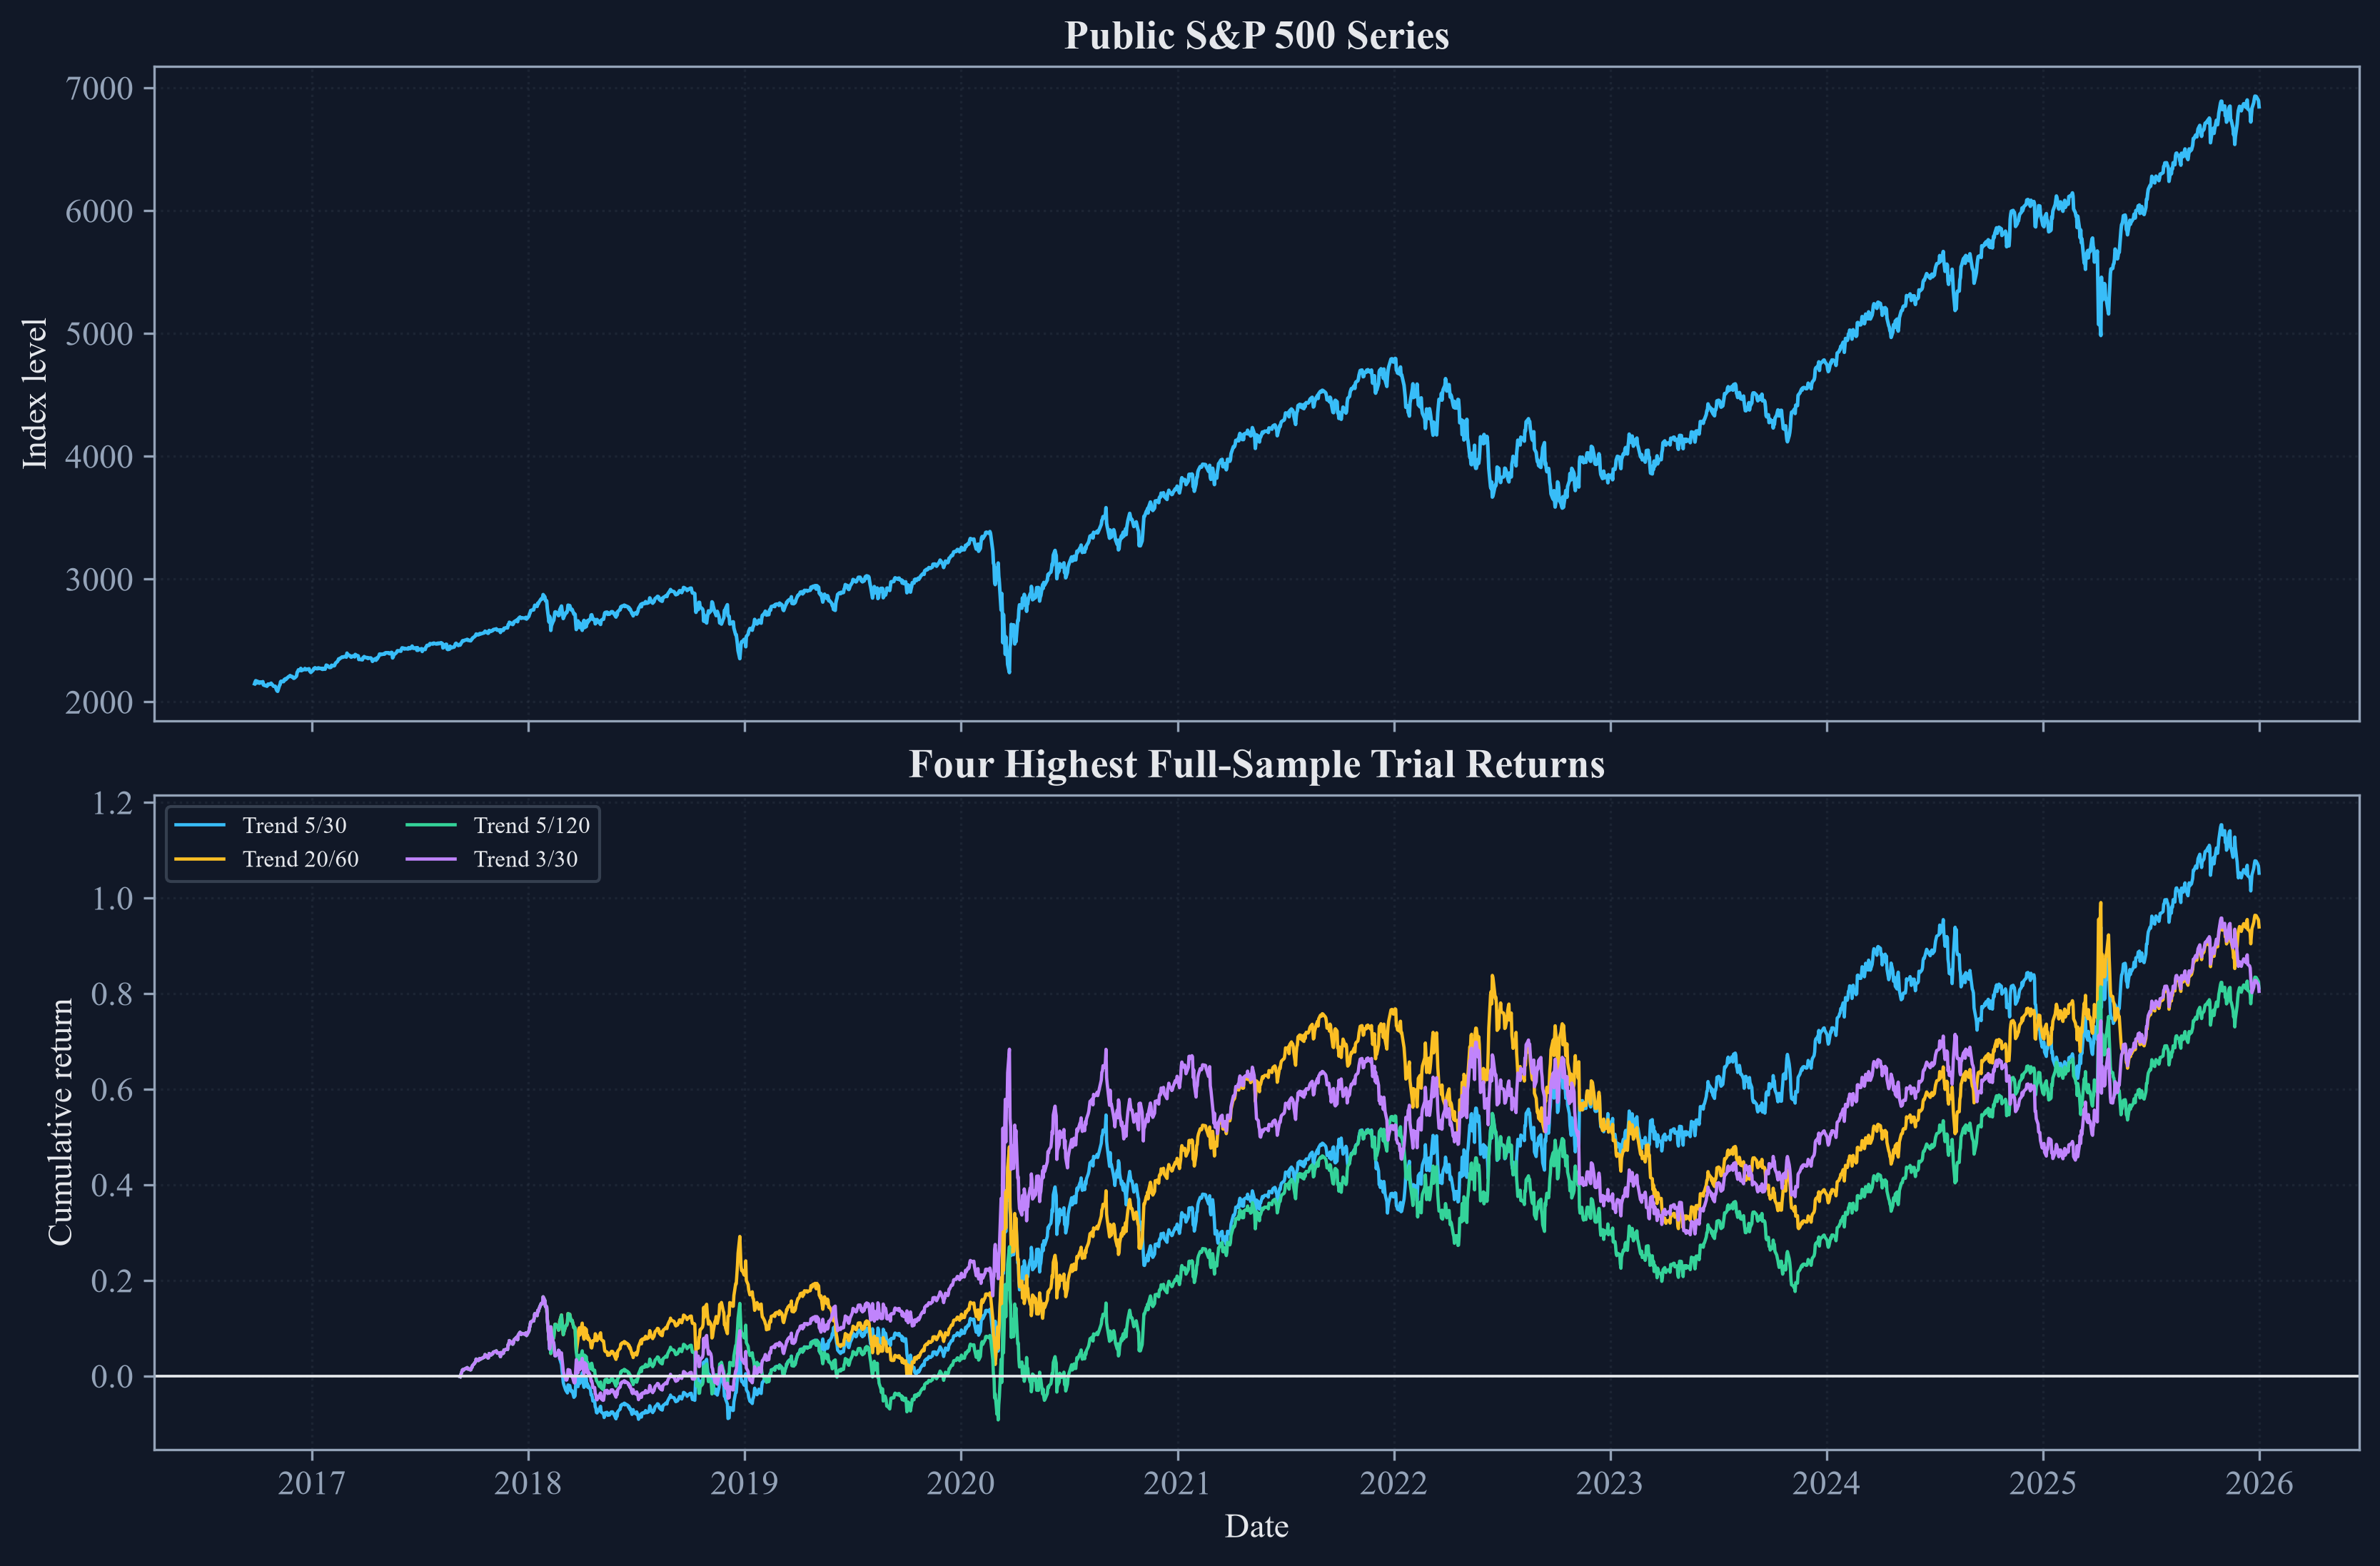

In [2]:
data_provenance = pd.DataFrame({'Field': ['Series', 'Provider', 'Source', 'Retrieved', 'First price', 'Last price', 'Price observations', 'Trial observations', 'Trials'], 'Value': ['S&P 500', 'Federal Reserve Bank of St. Louis', DATA_URL, '2026-09-28', str(prices.index.min().date()), str(prices.index.max().date()), f'{len(prices):,}', f'{len(performances):,}', len(performances.columns)]})
full_scores = score_vector(performances.to_numpy()) * np.sqrt(252)
full_performance = pd.DataFrame({'Trial': np.arange(1, performances.shape[1] + 1), 'Name': performances.columns, 'Annual return': performances.mean().to_numpy() * 252, 'Annual volatility': performances.std(ddof=0).to_numpy() * np.sqrt(252), 'Sharpe ratio': full_scores, 'Cumulative return': np.exp(performances.sum().to_numpy()) - 1})
trial_family_summary = strategy_catalog.groupby(['Rule', 'Fast span'], as_index=False).agg(Trials=('Trial', 'size'), Smallest_slow_span=('Slow span', 'min'), Largest_slow_span=('Slow span', 'max')).rename(columns={'Smallest_slow_span': 'Smallest slow span', 'Largest_slow_span': 'Largest slow span'})
leading_trials = full_performance.sort_values(['Sharpe ratio', 'Trial'], ascending=[False, True]).head(8)
save_table(data_provenance, 'data_provenance', 'Public observations used in Chapter 17.', 'tab:chapter17-data-provenance')
save_table(strategy_catalog, 'strategy_catalog', 'The thirty-two synchronized strategy trials.', 'tab:chapter17-strategy-catalog')
save_table(full_performance, 'full_sample_performance', 'Full-sample descriptions of the strategy trials.', 'tab:chapter17-full-performance')
save_table(trial_family_summary, 'trial_family_summary', 'Counts and slow-span ranges in the public trial family.', 'tab:chapter17-trial-family')
save_table(leading_trials, 'leading_full_sample_trials', 'The eight highest full-sample Sharpe ratios in the public trial family.', 'tab:chapter17-leading-trials')
display(data_provenance)
display(strategy_catalog)
display(full_performance)
display(trial_family_summary)
display(leading_trials)
leading_names = full_performance.nlargest(4, 'Sharpe ratio')['Name'].tolist()
figure, axes = plt.subplots(2, 1, figsize=(11.0, 7.2), sharex=True, constrained_layout=True)
axes[0].plot(prices, color=palette['cyan'], linewidth=1.2)
axes[0].set_title('Public S&P 500 Series')
axes[0].set_ylabel('Index level')
axes[0].grid(alpha=0.3)
colors = [palette['cyan'], palette['amber'], palette['green'], palette['violet']]
for color, name in zip(colors, leading_names):
    axes[1].plot(np.exp(performances[name].cumsum()) - 1, label=name, color=color, linewidth=1.1)
axes[1].axhline(0, color=palette['text'], linewidth=0.9)
axes[1].set_title('Four Highest Full-Sample Trial Returns')
axes[1].set_ylabel('Cumulative return')
axes[1].set_xlabel('Date')
axes[1].legend(ncol=2, fontsize=8)
axes[1].grid(alpha=0.3)
figure.savefig(FIGURES / 'public_sp500_trials.png', bbox_inches='tight', dpi=300)
figure.savefig(FIGURES / 'public_sp500_trials.pdf', bbox_inches='tight')
display(Image(filename=str(FIGURES / 'public_sp500_trials.png')))
plt.close(figure)


An even number of consecutive groups divides the rows without changing their order:

$$
M=\begin{bmatrix}M_1^{\mathsf T}&\cdots&M_S^{\mathsf T}\end{bmatrix}^{\mathsf T},
\qquad M_s\in\mathbb R^{T_s\times N},
\qquad \sum_{s=1}^{S}T_s=T.
$$

Here, $S$ is an even number of time groups, $M_s$ is group $s$, $T_s$ is its number of observations, $N$ is the number of trials, and the transpose marks show that the groups are joined down the rows in their original time order.

## Symmetric Combinations

Choosing half of the groups for training produces this many ordered training and testing assignments:

$$
C_S=\binom{S}{S/2}=\frac{S!}{(S/2)!(S/2)!}.
$$

Here, $C_S$ is the number of symmetric combinations, $S$ is the even number of groups, $S/2$ is the number assigned to each side, and the factorial formula counts every distinct choice of training groups whose complement becomes the testing set.

,Group,First date,Last date,Observations
0,1,2017-09-08,2018-09-21,262
1,2,2018-09-24,2019-10-08,262
2,3,2019-10-09,2020-10-20,261
3,4,2020-10-21,2021-11-02,261
4,5,2021-11-03,2022-11-15,261
5,6,2022-11-16,2023-11-30,261
6,7,2023-12-01,2024-12-13,261
7,8,2024-12-16,2025-12-31,261


,Quantity,Value
0,Time groups,8
1,Groups on each side,4
2,Symmetric combinations,70
3,Complement pairs,35
4,Smallest training set,1044
5,Largest training set,1046
6,Smallest testing set,1044
7,Largest testing set,1046


,Combination,Training groups,Testing groups,Training observations,Testing observations
0,1,"1, 2, 3, 4","5, 6, 7, 8",1046,1044
1,2,"1, 2, 3, 5","4, 6, 7, 8",1046,1044
2,3,"1, 2, 3, 6","4, 5, 7, 8",1046,1044
3,4,"1, 2, 3, 7","4, 5, 6, 8",1046,1044
4,5,"1, 2, 3, 8","4, 5, 6, 7",1046,1044
5,6,"1, 2, 4, 5","3, 6, 7, 8",1046,1044
6,7,"1, 2, 4, 6","3, 5, 7, 8",1046,1044
7,8,"1, 2, 4, 7","3, 5, 6, 8",1046,1044
8,9,"1, 2, 4, 8","3, 5, 6, 7",1046,1044
9,10,"1, 2, 5, 6","3, 4, 7, 8",1046,1044


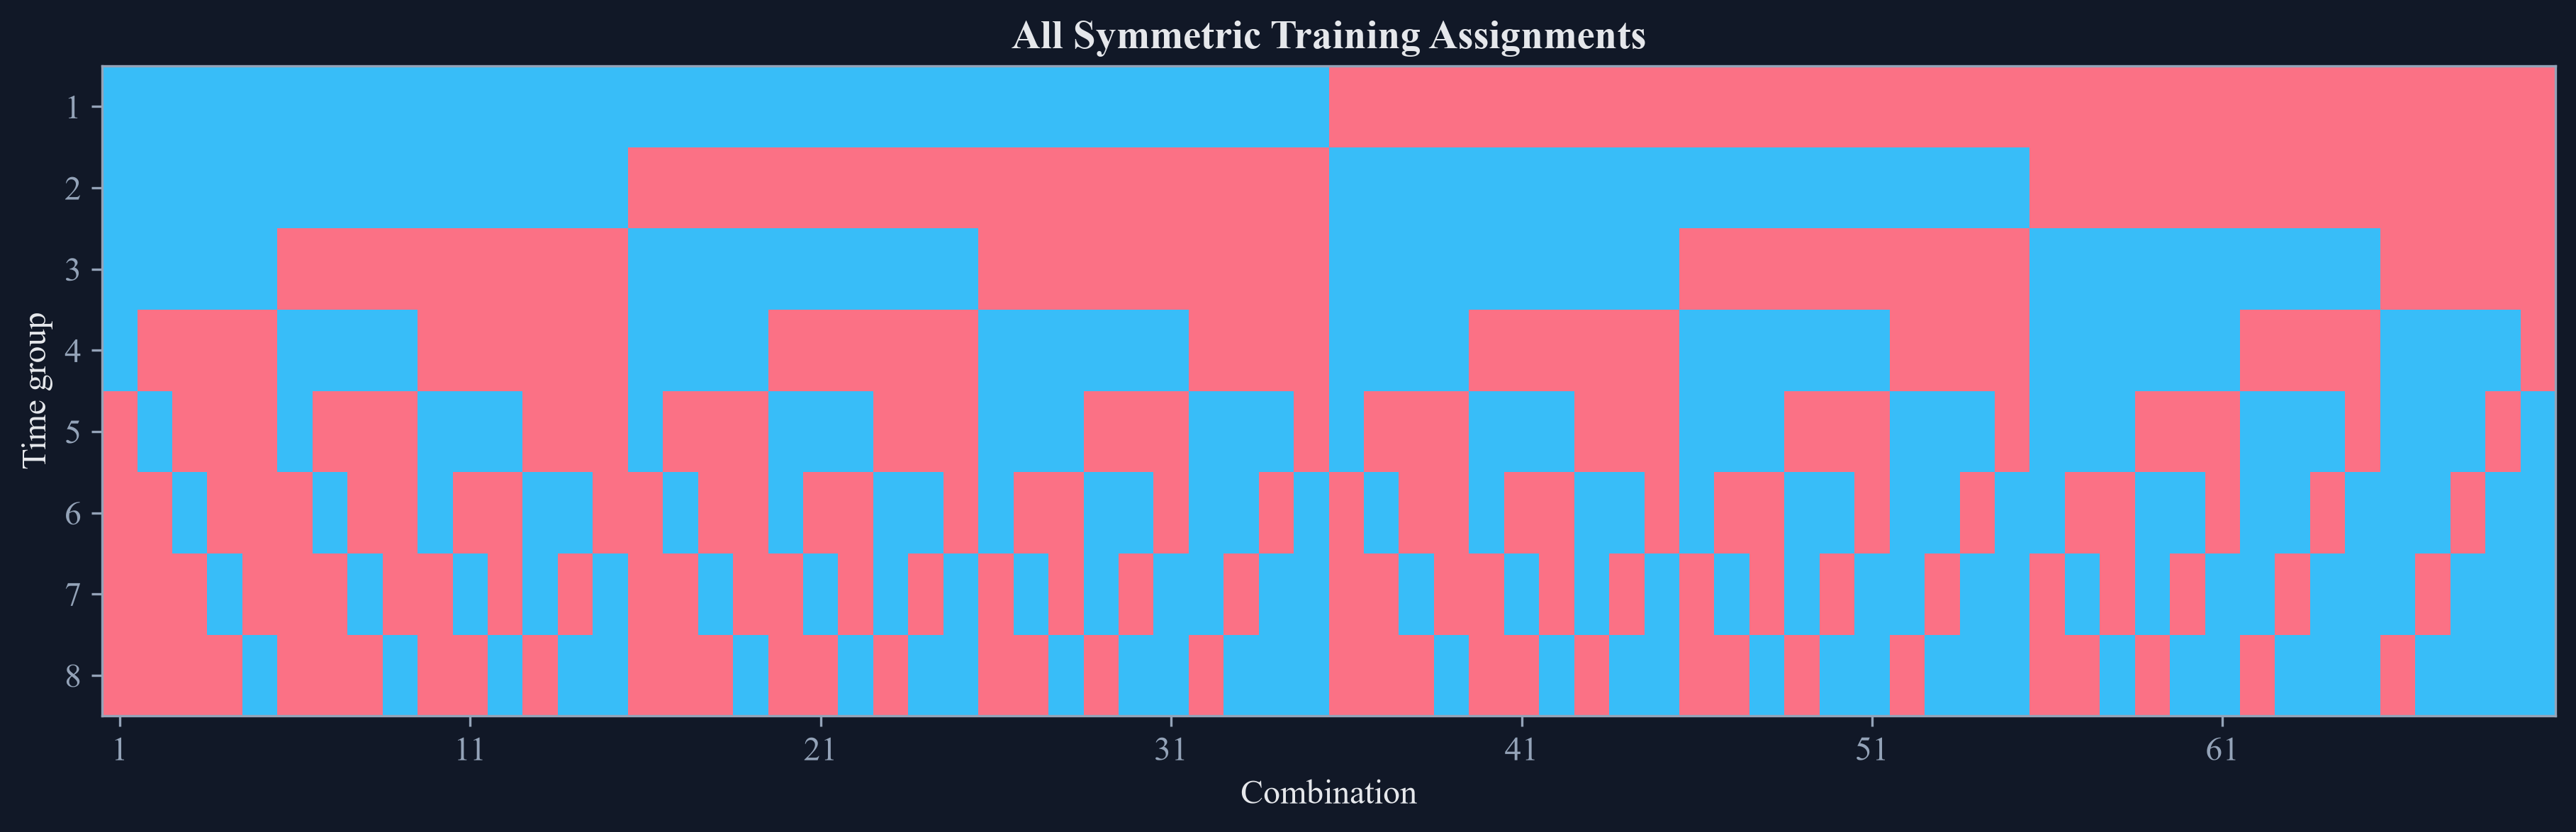

In [3]:
n_partitions = 8
groups = np.array_split(np.arange(len(performances)), n_partitions)
group_rows = []
for group_number, indices in enumerate(groups, start=1):
    dates = performances.index[indices]
    group_rows.append({"Group": group_number, "First date": str(dates.min().date()), "Last date": str(dates.max().date()), "Observations": len(indices)})
group_summary = pd.DataFrame(group_rows)
records = cscv_records(performances.to_numpy(), n_partitions, performances.columns)
complement_pairs = set()
for _, row in records.iterrows():
    train_key = tuple(int(value) for value in row["Training groups"].split(", "))
    test_key = tuple(int(value) for value in row["Testing groups"].split(", "))
    complement_pairs.add(tuple(sorted((train_key, test_key))))
combination_summary = pd.DataFrame({
    "Quantity": ["Time groups", "Groups on each side", "Symmetric combinations", "Complement pairs", "Smallest training set", "Largest training set", "Smallest testing set", "Largest testing set"],
    "Value": [n_partitions, n_partitions // 2, len(records), len(complement_pairs), records["Training observations"].min(), records["Training observations"].max(), records["Testing observations"].min(), records["Testing observations"].max()],
})
split_audit = records[["Combination", "Training groups", "Testing groups", "Training observations", "Testing observations"]].head(14)
save_table(group_summary, "time_group_summary", "Consecutive groups in the public symmetric split.", "tab:chapter17-time-groups")
save_table(combination_summary, "combination_summary", "Counts for the public symmetric split.", "tab:chapter17-combination-summary", fit=False)
save_table(split_audit, "split_audit", "The first fourteen symmetric training and testing assignments.", "tab:chapter17-split-audit")
display(group_summary)
display(combination_summary)
display(split_audit)

occupancy = np.zeros((n_partitions, len(records)), dtype=int)
for column, training_groups in enumerate(records["Training groups"]):
    for group in [int(value) - 1 for value in training_groups.split(", ")]:
        occupancy[group, column] = 1
figure, axis = plt.subplots(figsize=(12.0, 3.8), constrained_layout=True)
axis.imshow(occupancy, aspect="auto", interpolation="nearest", cmap=matplotlib.colors.ListedColormap([palette["rose"], palette["cyan"]]))
axis.set_title("All Symmetric Training Assignments")
axis.set_xlabel("Combination")
axis.set_ylabel("Time group")
axis.set_yticks(np.arange(n_partitions), np.arange(1, n_partitions + 1))
axis.set_xticks(np.arange(0, len(records), 10), np.arange(1, len(records) + 1, 10))
figure.savefig(FIGURES / "symmetric_split_map.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "symmetric_split_map.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "symmetric_split_map.png")))
plt.close(figure)

Every assignment has a complementary assignment with the two sides exchanged:

$$
A\subset\{1,\ldots,S\},\ |A|=S/2
\quad\Longrightarrow\quad
A^{\mathsf c}\subset\{1,\ldots,S\},\ |A^{\mathsf c}|=S/2.
$$

Here, $A$ is one set of training groups, $A^{\mathsf c}$ is its complement, $|A|$ denotes the number of groups in $A$, and the equality of the two sizes makes it possible to reuse each training half as a testing half.

## Preliminary Ranking Example

A simple rank summary averages a trial's rank across repeated splits:

$$
\overline q_n=\frac{1}{K}\sum_{k=1}^{K}q_{n,k}.
$$

Here, $q_{n,k}$ is the descending performance rank of trial $n$ in split $k$, $K$ is the number of splits, and $\overline q_n$ is the mean rank, so a smaller value indicates more consistently high performance.

,Trial,Split 1,Split 2,Split 3,Split 4
0,0,0.374540,0.950714,0.731994,0.598658
1,1,0.900000,0.200000,0.100000,0.300000
2,2,0.601115,0.708073,0.020584,0.969910
3,3,0.800000,0.750000,0.850000,0.700000
4,4,0.304242,0.524756,0.431945,0.291229
5,5,0.611853,0.139494,0.292145,0.366362


,Trial,Mean rank,Rank spread
3,3,1.75,0.500000
0,0,2.75,1.707825
2,2,3.50,2.081666
1,1,4,2
5,5,4.25,1.258306
4,4,4.75,1.500000


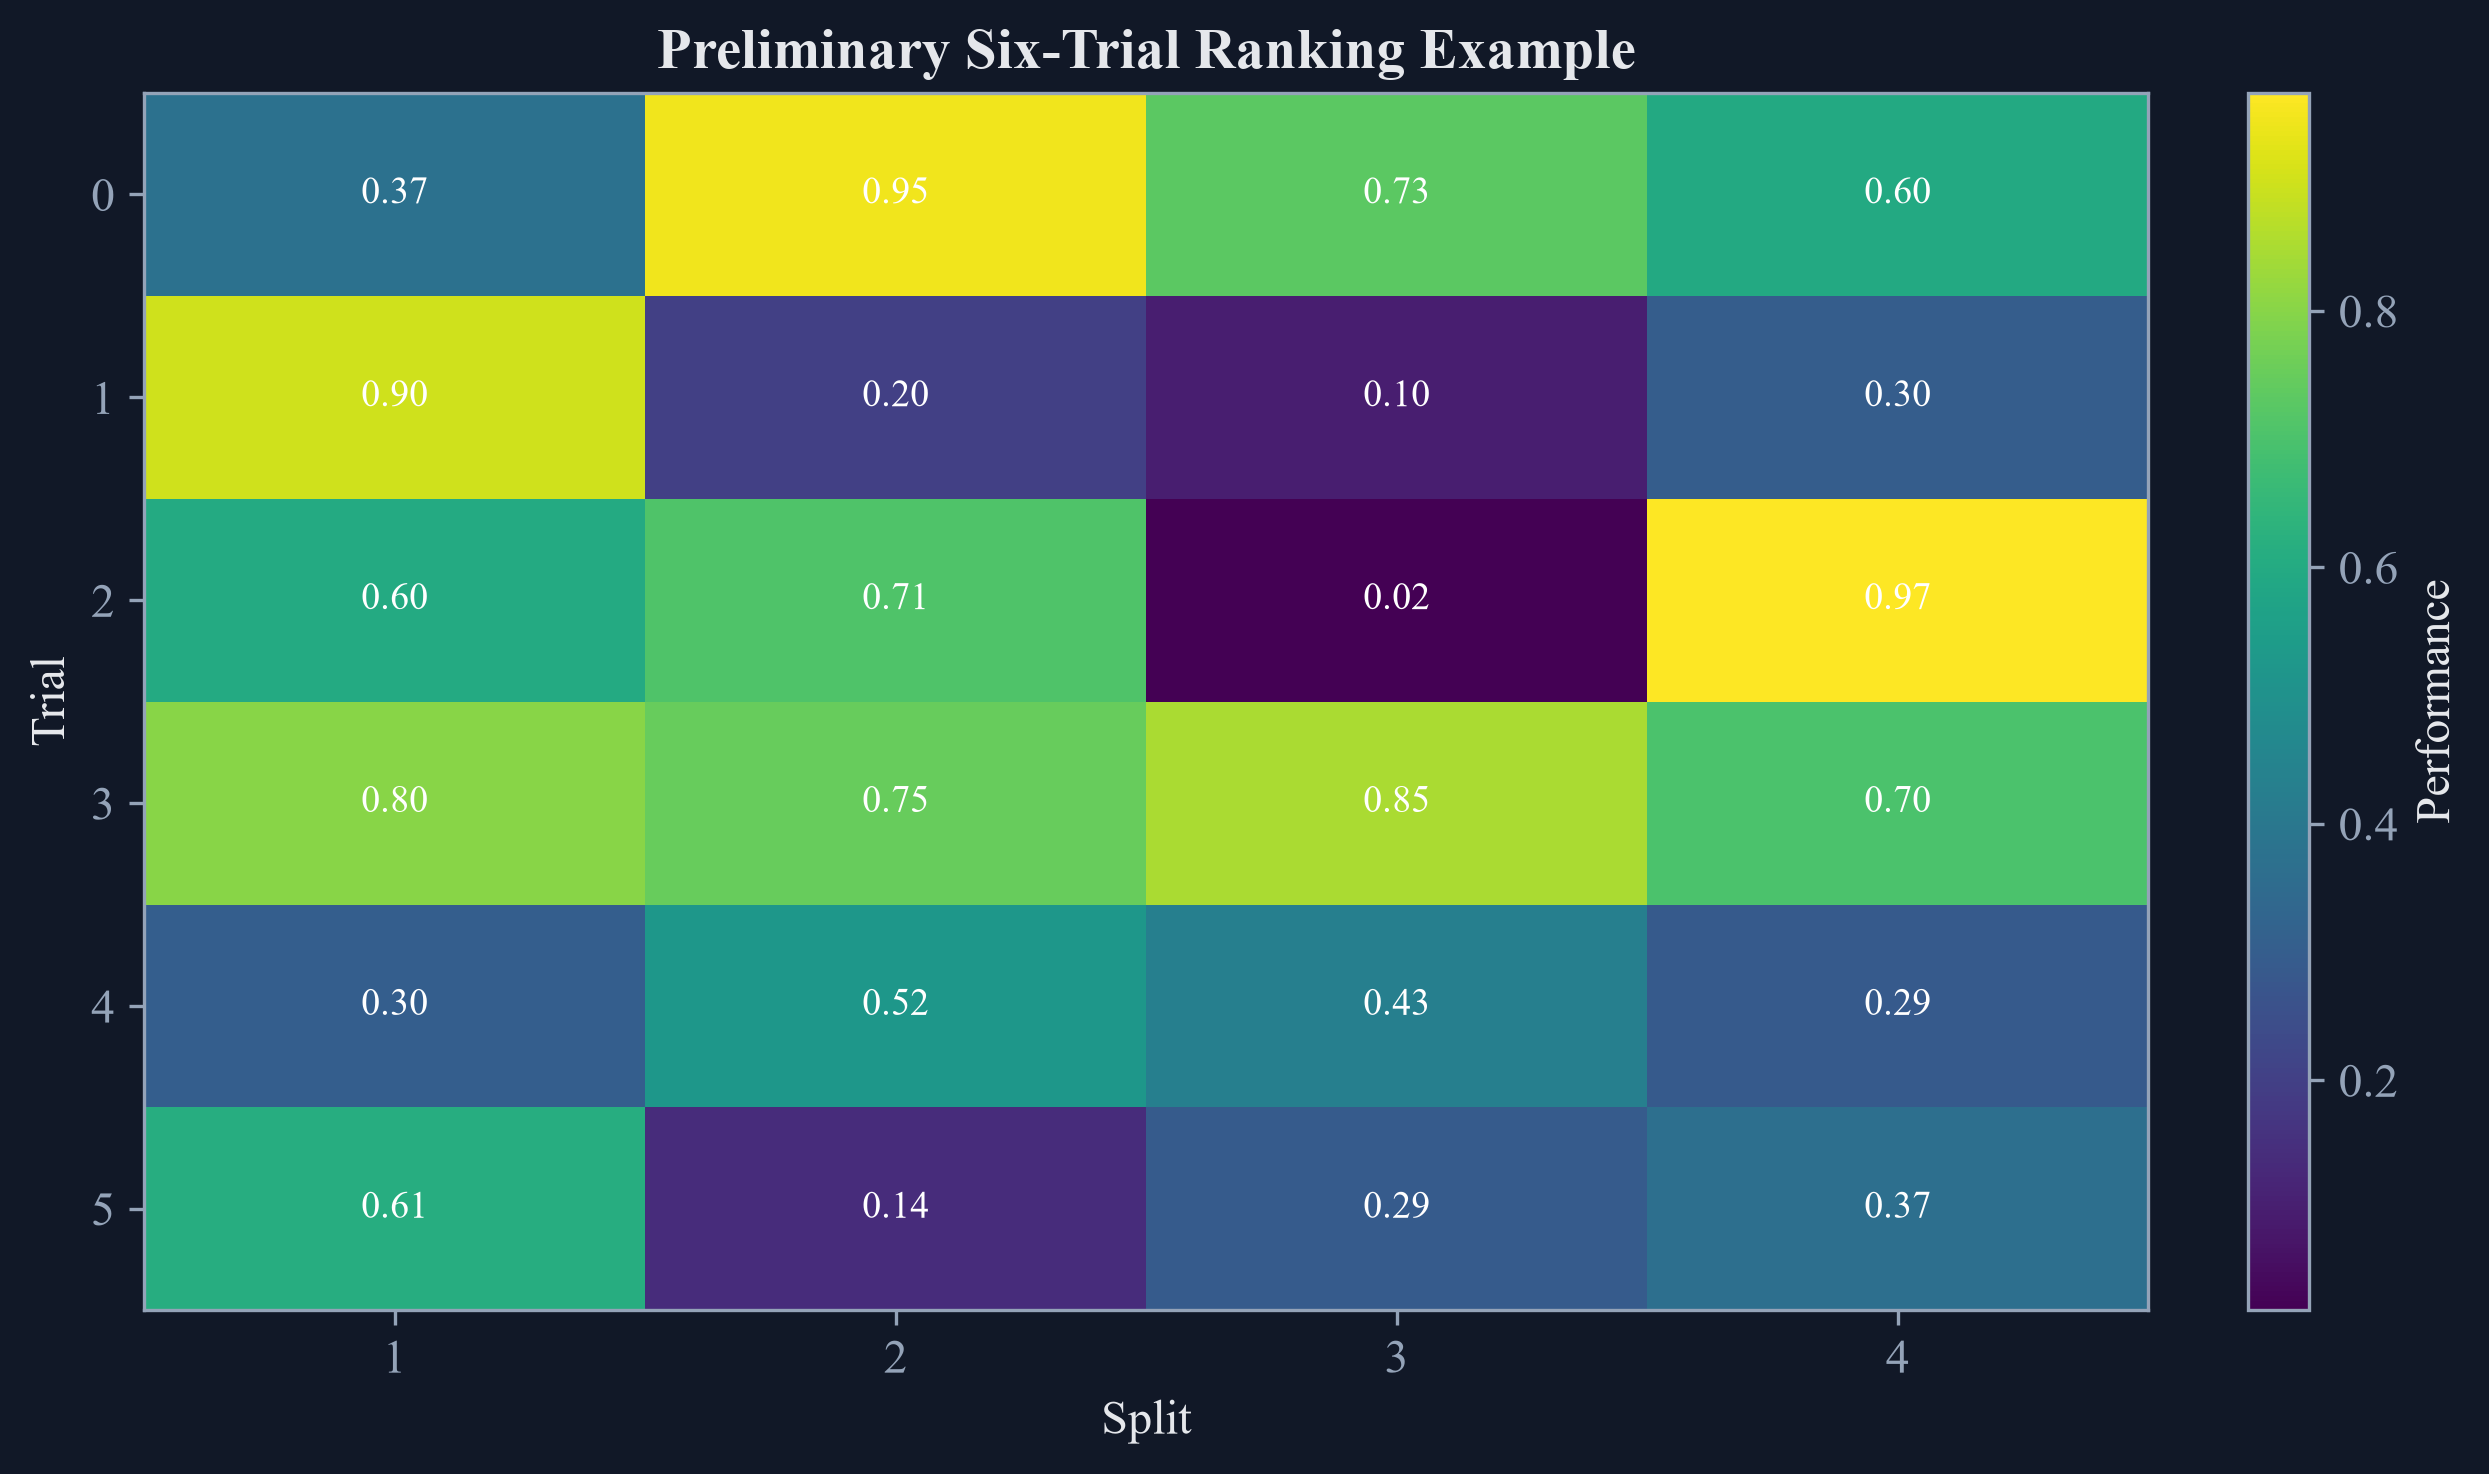

In [4]:
preliminary_rng = np.random.RandomState(42)
preliminary_matrix = pd.DataFrame(preliminary_rng.rand(6, 4), columns=["Split 1", "Split 2", "Split 3", "Split 4"])
preliminary_matrix.iloc[3] = [0.8, 0.75, 0.85, 0.7]
preliminary_matrix.iloc[1] = [0.9, 0.2, 0.1, 0.3]
preliminary_ranks = preliminary_matrix.rank(axis=0, ascending=False)
preliminary_summary = pd.DataFrame({"Trial": np.arange(6), "Mean rank": preliminary_ranks.mean(axis=1), "Rank spread": preliminary_ranks.std(axis=1)}).sort_values(["Mean rank", "Trial"])
preliminary_table = preliminary_matrix.reset_index(names="Trial")
save_table(preliminary_table, "preliminary_performance_matrix", "The preliminary six-trial ranking example.", "tab:chapter17-preliminary-matrix")
save_table(preliminary_summary, "preliminary_rank_summary", "Mean ranks in the preliminary ranking example.", "tab:chapter17-preliminary-ranks", fit=False)
display(preliminary_table)
display(preliminary_summary)

figure, axis = plt.subplots(figsize=(8.2, 4.8), constrained_layout=True)
image = axis.imshow(preliminary_matrix.to_numpy(), aspect="auto", cmap="viridis")
axis.set_title("Preliminary Six-Trial Ranking Example")
axis.set_xlabel("Split")
axis.set_ylabel("Trial")
axis.set_xticks(np.arange(4), np.arange(1, 5))
axis.set_yticks(np.arange(6), np.arange(6))
for row in range(6):
    for column in range(4):
        axis.text(column, row, f"{preliminary_matrix.iloc[row, column]:.2f}", ha="center", va="center", color="white", fontsize=9)
figure.colorbar(image, ax=axis, label="Performance")
figure.savefig(FIGURES / "preliminary_ranking_example.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "preliminary_ranking_example.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "preliminary_ranking_example.png")))
plt.close(figure)

## Tests

In [5]:
assert prices.index.is_monotonic_increasing
assert not prices.index.has_duplicates
assert performances.shape[1] == 32
assert strategy_catalog.shape == (32, 5)
assert trial_family_summary.shape == (8, 5)
assert leading_trials.shape == (8, 6)
assert np.isfinite(performances.to_numpy()).all()
assert len(records) == math.comb(8, 4) == 70
assert len(complement_pairs) == 35
assert (occupancy.sum(axis=0) == 4).all()
assert (occupancy.sum(axis=1) == 35).all()
assert group_summary['Observations'].max() - group_summary['Observations'].min() <= 1
assert preliminary_summary.iloc[0]['Trial'] == 3
assert preliminary_summary.iloc[-1]['Trial'] == 4
assert (FIGURES / 'public_sp500_trials.pdf').is_file()
assert (FIGURES / 'symmetric_split_map.pdf').is_file()
assert (FIGURES / 'preliminary_ranking_example.pdf').is_file()
assert (TABLES / 'data_provenance.tex').is_file()
assert (TABLES / 'strategy_catalog.tex').is_file()
assert (TABLES / 'full_sample_performance.tex').is_file()
assert (TABLES / 'trial_family_summary.tex').is_file()
assert (TABLES / 'leading_full_sample_trials.tex').is_file()
assert (TABLES / 'time_group_summary.tex').is_file()
assert (TABLES / 'combination_summary.tex').is_file()
assert (TABLES / 'split_audit.tex').is_file()
assert (TABLES / 'preliminary_performance_matrix.tex').is_file()
assert (TABLES / 'preliminary_rank_summary.tex').is_file()
